# Seasonality Modeling of Timeseries Data

In [1]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

In [289]:
#corrected data with means for each group of 5 animals
wnt_data_corrected = pd.read_csv("wnt_corrected.csv")
#unique indexes for sanity checking
wnt_data_corrected.index = wnt_data_corrected["gene"] + wnt_data_corrected["Time.Point"].apply(lambda x: x.replace("Day ", "D."))
#get relative error bar positions values as offsets of means
wnt_data_corrected["lower_err"] = abs(wnt_data_corrected["lower"] - wnt_data_corrected["mean"])
wnt_data_corrected["upper_err"] = abs(wnt_data_corrected["upper"] - wnt_data_corrected["mean"])
del wnt_data_corrected["Unnamed: 0"]

In [290]:
wnt_data_corrected


,gene,Time.Point,mean,sd,lower,upper,lower_err,upper_err
wnt9D.1,wnt9,Day 1,0.138649,0.211341,-0.200350,0.473402,0.338999,0.334753
wnt9D.14,wnt9,Day 14,0.257552,0.211944,-0.083801,0.600797,0.341353,0.343245
wnt9D.21,wnt9,Day 21,-0.071788,0.213450,-0.428650,0.281111,0.356861,0.352899
wnt9D.3,wnt9,Day 3,0.771689,0.215710,0.408644,1.121518,0.363045,0.349830
wnt9D.5,wnt9,Day 5,0.462917,0.214714,0.120594,0.832663,0.342323,0.369746
wnt9D.7,wnt9,Day 7,0.302412,0.216310,-0.043544,0.655283,0.345956,0.352871
wnt6D.1,wnt6,Day 1,-0.620026,0.367346,-1.195549,-0.041525,0.575524,0.578501
wnt6D.14,wnt6,Day 14,0.958533,0.368885,0.362158,1.553291,0.596375,0.594759
wnt6D.21,wnt6,Day 21,0.770463,0.371845,0.153110,1.382216,0.617353,0.611753
wnt6D.3,wnt6,Day 3,1.381159,0.361248,0.788282,1.963123,0.592877,0.581964


In [291]:
summed = {}
data = {}
wnt_data_corrected["time"] = wnt_data_corrected["Time.Point"].str.replace("Day ", "").astype(int)
days = sorted(wnt_data_corrected["Time.Point"].unique(), key = lambda x: int(x.split()[1]))
for i in wnt_data_corrected["gene"].unique():
    temp_table = wnt_data_corrected[wnt_data_corrected["gene"] == i].sort_values(by="time")
    #get data points and error bar offsets
    data[i] = [temp_table["mean"], temp_table["lower_err"], temp_table["upper_err"]]
for i in days:
    #return a series of all entries per day, in consistent gene order
    summed[i] = wnt_data_corrected[wnt_data_corrected["Time.Point"] == i].sort_values(by="gene")["mean"]

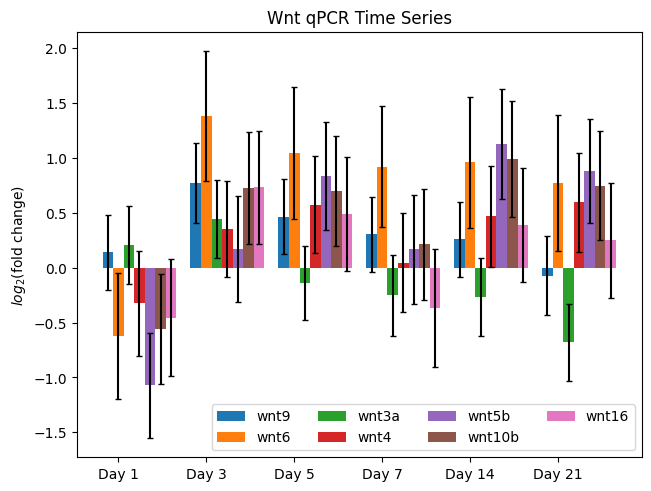

In [292]:
#set tick positions and offsets
x = np.arange(len(days))
width = 0.12
multiplier = 0
fig, ax = plt.subplots(layout='constrained')
#loop through for each day to add bar clusters
for attribute, measurements in data.items():
    #measurements - 0:means, 1: low error bar, 2: high error bar
    error = np.array(measurements[1],measurements[2])
    offset = width * multiplier
    rects = ax.bar(x + offset, list(measurements[0]), width, label=attribute, yerr=error, capsize=2)
    multiplier += 1
ax.set_ylabel('$log_2$(fold change)')
ax.set_title("Wnt qPCR Time Series")
ax.set_xticks(x + width, days)
ax.legend(loc='lower right', ncols=4,  )

Text(0, 0.5, '$log_2$(fold change)')

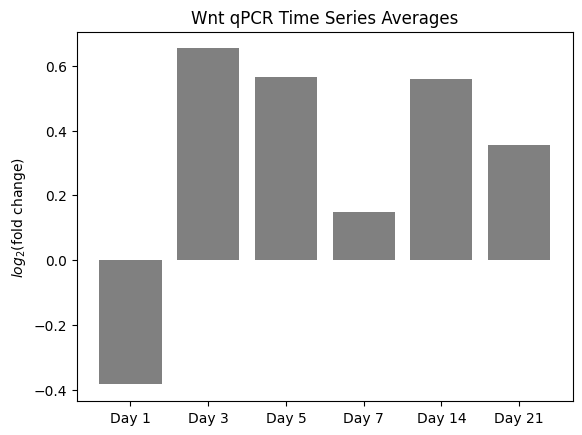

In [293]:
#plot averages as a bar plot
plt.bar(x, [sum(summed[x])/len(summed[x]) for x in summed.keys()], tick_label = days, color = "grey")
plt.title("Wnt qPCR Time Series Averages")
plt.ylabel('$log_2$(fold change)')

Text(0, 0.5, '$log_2$(fold change)')

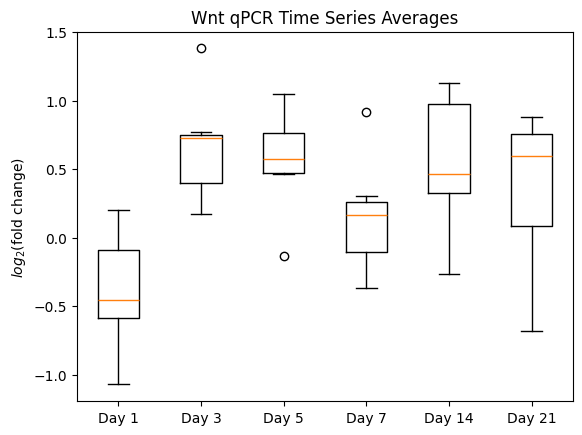

In [294]:
#plot averages as a box and whisker plot
whiskerplot = plt.boxplot([summed[x] for x in summed.keys()], labels = days)
plt.title("Wnt qPCR Time Series Averages")
plt.ylabel('$log_2$(fold change)')

In [38]:
wnt_data = pd.read_csv("wnt_Ct_data.csv")

wnt_data

,sample,Time.Point,wnt9,tubb,ubc,tuba,wnt3a,wnt6,wnt4,wnt5b,wnt10b,wnt16
0,n1,Norm,29.563492,24.976870,22.791037,28.139087,29.640754,31.783582,30.396169,30.481372,30.829658,29.145324
1,d1.1,Day 1,28.224591,24.288943,21.669533,26.423828,28.027168,30.138847,29.061069,30.276762,29.502053,28.458560
2,d3.1,Day 3,28.560151,23.848086,23.109331,27.170086,28.249953,29.578916,28.995940,29.416930,28.993956,28.153990
3,d5.1,Day 5,30.013667,26.126488,23.164960,28.260235,30.048953,31.124424,29.887777,29.911594,30.071974,29.375462
4,d7.1,Day 7,30.148267,26.458664,23.304680,28.329055,30.370738,31.097431,31.040755,31.393495,31.107037,30.874375
...,...,...,...,...,...,...,...,...,...,...,...,...
65,d21.1,Day 21,29.610843,27.234518,23.448950,27.486413,30.195694,31.410451,29.364328,29.486246,29.564727,28.515772
66,d21.2,Day 21,29.680177,25.297983,23.448950,27.126198,30.340857,31.649067,29.739906,29.830998,30.405080,29.347734
67,d21.3,Day 21,30.205475,26.788138,23.448950,27.673724,29.975691,31.197480,29.768606,30.260086,30.133178,29.519165
68,d21.4,Day 21,31.166177,27.451667,23.448950,28.019987,31.363980,31.303421,30.362100,30.621000,30.784046,30.287514


In [39]:
## Filter out Norm Time.Point rows
wnt_data = wnt_data[~wnt_data['Time.Point'].str.contains("Norm")]

## Rename Time.Point to time_point and derive days as numbers
wnt_data['time_point'] = wnt_data['Time.Point'].str.replace("Day ", "", regex=False)
wnt_data['time_point'] = wnt_data['time_point'].astype(int)

## Turn time_point into a date 1/X/2025
wnt_data['date'] = pd.to_datetime("2024-12-31") + pd.to_timedelta(wnt_data['time_point'], unit='D')

## Drop Time.Point columns
wnt_data = wnt_data.drop(columns=['Time.Point', 'time_point'])

wnt_data.head()

C:\Users\Colby\AppData\Local\Temp\ipykernel_17476\3501480515.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wnt_data['time_point'] = wnt_data['Time.Point'].str.replace("Day ", "", regex=False)
C:\Users\Colby\AppData\Local\Temp\ipykernel_17476\3501480515.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wnt_data['time_point'] = wnt_data['time_point'].astype(int)
C:\Users\Colby\AppData\Local\Temp\ipykernel_17476\3501480515.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,sample,wnt9,tubb,ubc,tuba,wnt3a,wnt6,wnt4,wnt5b,wnt10b,wnt16,date
1,d1.1,28.224591,24.288943,21.669533,26.423828,28.027168,30.138847,29.061069,30.276762,29.502053,28.458560,2025-01-01
2,d3.1,28.560151,23.848086,23.109331,27.170086,28.249953,29.578916,28.995940,29.416930,28.993956,28.153990,2025-01-03
3,d5.1,30.013667,26.126488,23.164960,28.260235,30.048953,31.124424,29.887777,29.911594,30.071974,29.375462,2025-01-05
4,d7.1,30.148267,26.458664,23.304680,28.329055,30.370738,31.097431,31.040755,31.393495,31.107037,30.874375,2025-01-07
5,d14.1,30.386581,26.585809,24.431493,28.617198,30.572244,32.006659,31.112600,30.766577,30.978563,30.261393,2025-01-14


In [81]:
## Pivot to get sum of counts by gene, ordered by time_point

wnt_data_pvt = wnt_data.groupby('date').sum() \
    .reset_index() \
    .melt(id_vars=['date'],
          value_vars=['wnt9', 'tubb', 'ubc', 'tuba', 'wnt3a', 'wnt6', 'wnt4', 'wnt5b', 'wnt10b', 'wnt16'],
          var_name='gene',
          value_name='count') \
    .set_index('date')

wnt_data_pvt.index = pd.PeriodIndex(wnt_data_pvt.index, freq='D')

wnt_data_pvt.head(6)

,gene,count
date,,
2025-01-01,wnt9,282.692233
2025-01-03,wnt9,287.588320
2025-01-05,wnt9,294.983074
2025-01-07,wnt9,298.997593
2025-01-14,wnt9,308.794787
2025-01-21,wnt9,300.946560


In [ ]:
def get_gene_data(gene_name:str) -> pd.DataFrame:
    gene_data = wnt_data_pvt[wnt_data_pvt['gene'] == gene_name].copy()[['count']]
    gene_data.index = pd.PeriodIndex(gene_data.index, freq='D')
    return gene_data

# wnt9_data = wnt_data_pvt[wnt_data_pvt['gene'] == 'wnt9'].copy()[['count']]
# wnt9_data = wnt_data_pvt[wnt_data_pvt['gene'] == 'wnt9'].copy()[['count']]

# wnt9_data

## Time Series Decomposition

Time series decomposition divides the data into its trend, seasonal, and residual components.

In [ ]:
## Perform time series decomposition
## Genes: ['wnt9', 'tubb', 'ubc', 'tuba', 'wnt3a', 'wnt6', 'wnt4', 'wnt5b', 'wnt10b', 'wnt16']

wnt9_decomp = seasonal_decompose(get_gene_data('wnt9'), model='stl', period=1)
tubb_decomp = seasonal_decompose(get_gene_data('tubb'), model='stl', period=1)
ubc_decomp = seasonal_decompose(get_gene_data('ubc'), model='stl', period=1)
tuba_decomp = seasonal_decompose(get_gene_data('tuba'), model='stl', period=1)
wnt3a_decomp = seasonal_decompose(get_gene_data('wnt3a'), model='stl', period=1)
wnt6_decomp = seasonal_decompose(get_gene_data('wnt6'), model='stl', period=1)
wnt4_decomp = seasonal_decompose(get_gene_data('wnt4'), model='stl', period=1)
wnt5b_decomp = seasonal_decompose(get_gene_data('wnt5b'), model='stl', period=1)
wnt10b_decomp = seasonal_decompose(get_gene_data('wnt10b'), model='stl', period=1)
wnt16_decomp = seasonal_decompose(get_gene_data('wnt16'), model='stl', period=1)


In [ ]:
wnt_decomp_df = pd.DataFrame({
    "resid_wnt9": wnt9_decomp.resid,
    "seasonal_wnt9": wnt9_decomp.seasonal,
    "trend_wnt9": wnt9_decomp.trend,
    "weights_wnt9": wnt9_decomp.weights,
    "resid_tubb": tubb_decomp.resid,
    "seasonal_tubb": tubb_decomp.seasonal,
    "trend_tubb": tubb_decomp.trend,
    "weights_tubb": tubb_decomp.weights,
    "resid_ubc": ubc_decomp.resid,
    "seasonal_ubc": ubc_decomp.seasonal,
    "trend_ubc": ubc_decomp.trend,
    "weights_ubc": ubc_decomp.weights,
    "resid_tuba": tuba_decomp.resid,
    "seasonal_tuba": tuba_decomp.seasonal,
    "trend_tuba": tuba_decomp.trend,
    "weights_tuba": tuba_decomp.weights,
    "resid_wnt3a": wnt3a_decomp.resid,
    "seasonal_wnt3a": wnt3a_decomp.seasonal,
    "trend_wnt3a": wnt3a_decomp.trend,
    "weights_wnt3a": wnt3a_decomp.weights,
    "resid_wnt6": wnt6_decomp.resid,
    "seasonal_wnt6": wnt6_decomp.seasonal,
    "trend_wnt6": wnt6_decomp.trend,
    "weights_wnt6": wnt6_decomp.weights,
    "resid_wnt4": wnt4_decomp.resid,
    "seasonal_wnt4": wnt4_decomp.seasonal,
    "trend_wnt4": wnt4_decomp.trend,
    "weights_wnt4": wnt4_decomp.weights,
    "resid_wnt5b": wnt5b_decomp.resid,
    "seasonal_wnt5b": wnt5b_decomp.seasonal,
    "trend_wnt5b": wnt5b_decomp.trend,
    "weights_wnt5b": wnt5b_decomp.weights,
    "resid_wnt10b": wnt10b_decomp.resid,
    "seasonal_wnt10b": wnt10b_decomp.seasonal,
    "trend_wnt10b": wnt10b_decomp.trend,
    "weights_wnt10b": wnt10b_decomp.weights,
    "resid_wnt16": wnt16_decomp.resid,
    "seasonal_wnt16": wnt16_decomp.seasonal,
    "trend_wnt16": wnt16_decomp.trend,
    "weights_wnt16": wnt16_decomp.weights,
})

## Rename index to 'date' for consistency
wnt_decomp_df.index.name = 'date'
## Turn index into a column
wnt_decomp_df.reset_index(inplace=True)

wnt_decomp_df.head()

,date,resid_wnt9,seasonal_wnt9,trend_wnt9,weights_wnt9,resid_tubb,seasonal_tubb,trend_tubb,weights_tubb,resid_ubc,...,trend_wnt5b,weights_wnt5b,resid_wnt10b,seasonal_wnt10b,trend_wnt10b,weights_wnt10b,resid_wnt16,seasonal_wnt16,trend_wnt16,weights_wnt16
0,2025-01-01,0.0,0.0,282.692233,1.0,0.0,0.0,247.445965,1.0,0.0,...,302.934268,1.0,0.0,0.0,298.814182,1.0,0.0,0.0,284.986655,1.0
1,2025-01-03,0.0,0.0,287.588320,1.0,0.0,0.0,255.783208,1.0,0.0,...,301.328736,1.0,0.0,0.0,296.915433,1.0,0.0,0.0,283.900547,1.0
2,2025-01-05,0.0,0.0,294.983074,1.0,0.0,0.0,263.217745,1.0,0.0,...,298.661519,1.0,0.0,0.0,301.482121,1.0,0.0,0.0,290.737928,1.0
3,2025-01-07,0.0,0.0,298.997593,1.0,0.0,0.0,266.220062,1.0,0.0,...,307.947057,1.0,0.0,0.0,308.795831,1.0,0.0,0.0,301.657208,1.0
4,2025-01-14,0.0,0.0,308.794787,1.0,0.0,0.0,273.692681,1.0,0.0,...,307.325424,1.0,0.0,0.0,310.216340,1.0,0.0,0.0,303.216874,1.0


In [ ]:
wnt_decomp_df_long = pd.wide_to_long(wnt_decomp_df, stubnames=['resid', 'seasonal', 'trend', 'weights'], i=['date'], j='set', sep='_', suffix=r'\w+')

wnt_decomp_df_long.head()

,,resid,seasonal,trend,weights
date,set,,,,
2025-01-01,wnt9,0.0,0.0,282.692233,1.0
2025-01-03,wnt9,0.0,0.0,287.588320,1.0
2025-01-05,wnt9,0.0,0.0,294.983074,1.0
2025-01-07,wnt9,0.0,0.0,298.997593,1.0
2025-01-14,wnt9,0.0,0.0,308.794787,1.0


In [ ]:
wnt_decomp_df_long.to_csv("wnt_decomp_df_long.csv")